# Sales Analysis (Project 1)

### Loading and Inspecting the Dataset

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Superstore_sales_dataset.csv")

df["Order Date"] = pd.to_datetime(df["Order Date"], dayfirst=True)
df["Ship Date"] = pd.to_datetime(df["Ship Date"], dayfirst=True)

print(df.shape)

(9994, 21)


In [4]:
print(df.dtypes)

Row ID                    int64
Order ID                 object
Order Date       datetime64[ns]
Ship Date        datetime64[ns]
Ship Mode                object
Customer ID              object
Customer Name            object
Segment                  object
Country                  object
City                     object
State                    object
Postal Code               int64
Region                   object
Product ID               object
Category                 object
Sub-Category             object
Product Name             object
Sales                   float64
Quantity                  int64
Discount                float64
Profit                  float64
dtype: object


In [9]:
#Checking for missing values
print(df.isnull().sum()) 

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


In [7]:
print("Date range:", df["Order Date"].min(), "to", df["Order Date"].max())

Date range: 2014-01-03 00:00:00 to 2017-12-30 00:00:00


In [10]:
#Checking for duplicates
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


### Computing KPIs, Top Products, Top Regions and Seasonality

In [12]:
# --- Core KPIs ---
total_revenue = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()   # unique orders, not rows
avg_order_value = total_revenue / total_orders
profit_margin = total_profit / total_revenue * 100

print(f"Total Revenue:     {total_revenue:,.2f}")
print(f"Total Profit:      {total_profit:,.2f}")
print(f"Profit Margin:     {profit_margin:.2f}%")
print(f"Total Orders:      {total_orders:,}")
print(f"Avg Order Value:   {avg_order_value:,.2f}")

Total Revenue:     2,297,200.86
Total Profit:      286,397.02
Profit Margin:     12.47%
Total Orders:      5,009
Avg Order Value:   458.61


In [13]:
# --- Top regions ---
region_stats = df.groupby("Region")[["Sales", "Profit"]].sum().sort_values("Sales", ascending=False)
region_stats["Margin %"] = region_stats["Profit"] / region_stats["Sales"] * 100
print("\nRegion performance:")
print(region_stats.round(2))


Region performance:
             Sales     Profit  Margin %
Region                                 
West     725457.82  108418.45     14.94
East     678781.24   91522.78     13.48
Central  501239.89   39706.36      7.92
South    391721.90   46749.43     11.93


In [14]:
# --- Top 10 products by sales ---
top_products = (df.groupby("Product Name")["Sales"].sum()
                  .sort_values(ascending=False).head(10))
print("\nTop 10 products by sales:")
print(top_products.round(2))


Top 10 products by sales:
Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.82
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.38
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.48
HON 5400 Series Task Chairs for Big and Tall                                   21870.58
GBC DocuBind TL300 Electric Binding System                                     19823.48
GBC Ibimaster 500 Manual ProClick Binding System                               19024.50
Hewlett Packard LaserJet 3310 Copier                                           18839.69
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.90
GBC DocuBind P400 Electric Binding System                                      17965.07
High Speed Automatic Electric Letter Opener                                    17030.31
Name: Sales, dtype: float64


In [15]:
# --- Category and sub-category performance ---
category_stats = df.groupby("Category")[["Sales", "Profit"]].sum()
print("\nCategory performance:")
print(category_stats.round(2))

subcat_profit = df.groupby("Sub-Category")["Profit"].sum().sort_values()
print("\nSub-categories by profit (lowest first):")
print(subcat_profit.round(2))


Category performance:
                     Sales     Profit
Category                             
Furniture        741999.80   18451.27
Office Supplies  719047.03  122490.80
Technology       836154.03  145454.95

Sub-categories by profit (lowest first):
Sub-Category
Tables        -17725.48
Bookcases      -3472.56
Supplies       -1189.10
Fasteners        949.52
Machines        3384.76
Labels          5546.25
Art             6527.79
Envelopes       6964.18
Furnishings    13059.14
Appliances     18138.01
Storage        21278.83
Chairs         26590.17
Binders        30221.76
Paper          34053.57
Accessories    41936.64
Phones         44515.73
Copiers        55617.82
Name: Profit, dtype: float64


In [16]:
# --- Seasonality: sales by calendar month, across all years ---
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month

monthly_avg = df.groupby(["Year", "Month"])["Sales"].sum().groupby("Month").mean()
print("\nAverage monthly sales (across years):")
print(monthly_avg.round(2))


Average monthly sales (across years):
Month
1     23731.21
2     14937.81
3     51251.37
4     34440.53
5     38757.20
6     38179.67
7     36809.52
8     39761.02
9     76912.49
10    50080.75
11    88115.27
12    81323.38
Name: Sales, dtype: float64


In [17]:
# --- Yearly trend ---
yearly_sales = df.groupby("Year")["Sales"].sum()
print("\nSales by year:")
print(yearly_sales.round(2))


Sales by year:
Year
2014    484247.50
2015    470532.51
2016    609205.60
2017    733215.26
Name: Sales, dtype: float64


In [18]:
# Average discount by region (compare with the margin you saw)
print(df.groupby("Region")["Discount"].mean().round(3))

# Profit by discount level
df["Discount Band"] = pd.cut(
    df["Discount"],
    bins=[-0.01, 0, 0.2, 0.4, 1],
    labels=["No discount", "0-20%", "20-40%", "40%+"]
)
discount_impact = df.groupby("Discount Band", observed=True)["Profit"].agg(["sum", "mean", "count"])
print(discount_impact.round(2))

# Yearly sales trend
print(df.groupby("Year")["Sales"].sum().round(0))

Region
Central    0.240
East       0.145
South      0.147
West       0.109
Name: Discount, dtype: float64
                     sum    mean  count
Discount Band                          
No discount    320987.60   66.90   4798
0-20%          100785.47   26.50   3803
20-40%         -35817.47  -77.86    460
40%+           -99558.59 -106.71    933
Year
2014    484247.0
2015    470533.0
2016    609206.0
2017    733215.0
Name: Sales, dtype: float64


### Creating and Exporting Charts 

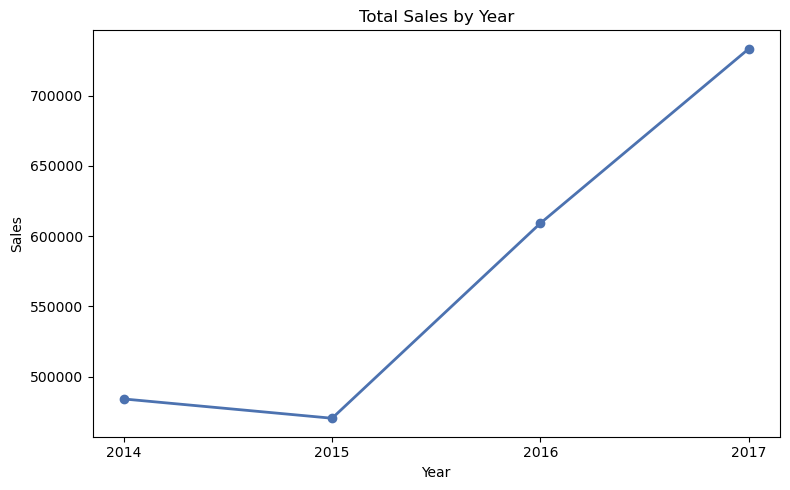

In [19]:
import numpy as np

# --- 1. Yearly sales trend ---
yearly_sales = df.groupby("Year")["Sales"].sum()
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(yearly_sales.index, yearly_sales.values, marker="o", color="#4C72B0", linewidth=2)
ax.set_xticks(yearly_sales.index)
ax.set_title("Total Sales by Year")
ax.set_xlabel("Year")
ax.set_ylabel("Sales")
plt.tight_layout()
plt.savefig("sales_by_year.png", dpi=150)
plt.show()

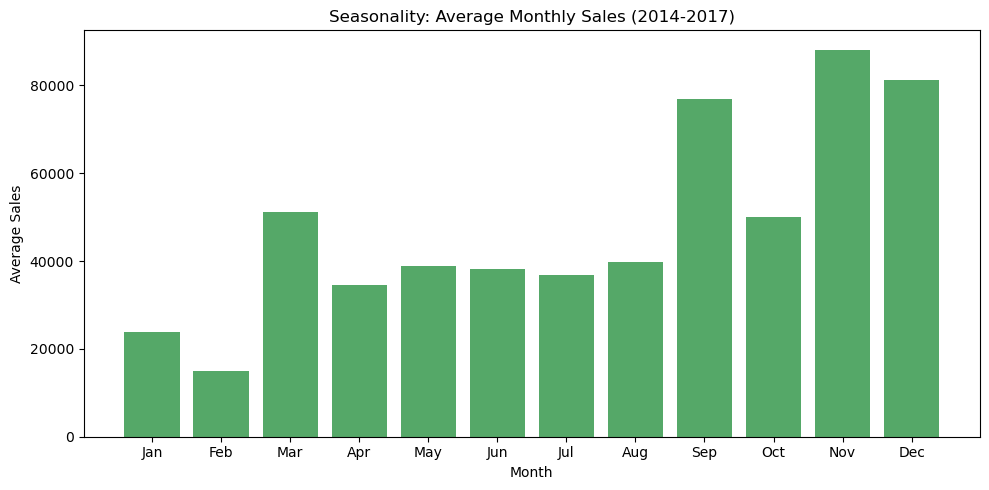

In [20]:
# --- 2. Seasonality: average sales by month ---
month_names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(month_names, monthly_avg.values, color="#55A868")
ax.set_title("Seasonality: Average Monthly Sales (2014-2017)")
ax.set_xlabel("Month")
ax.set_ylabel("Average Sales")
plt.tight_layout()
plt.savefig("seasonality.png", dpi=150)
plt.show()

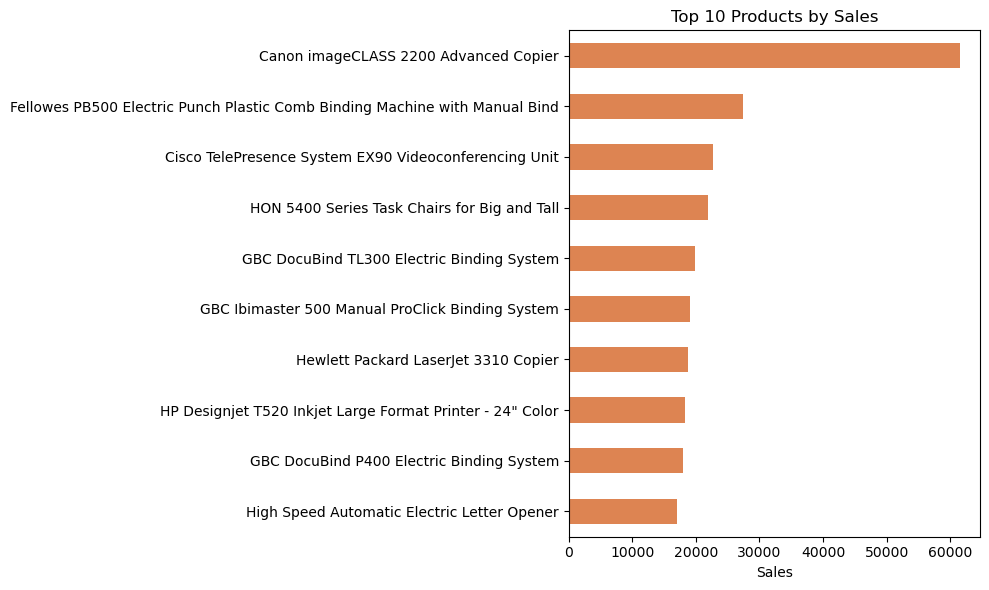

In [21]:
# --- 3. Top 10 products by sales ---
fig, ax = plt.subplots(figsize=(10, 6))
top_products.sort_values().plot(kind="barh", ax=ax, color="#DD8452")
ax.set_title("Top 10 Products by Sales")
ax.set_xlabel("Sales")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig("top_products.png", dpi=150)
plt.show()

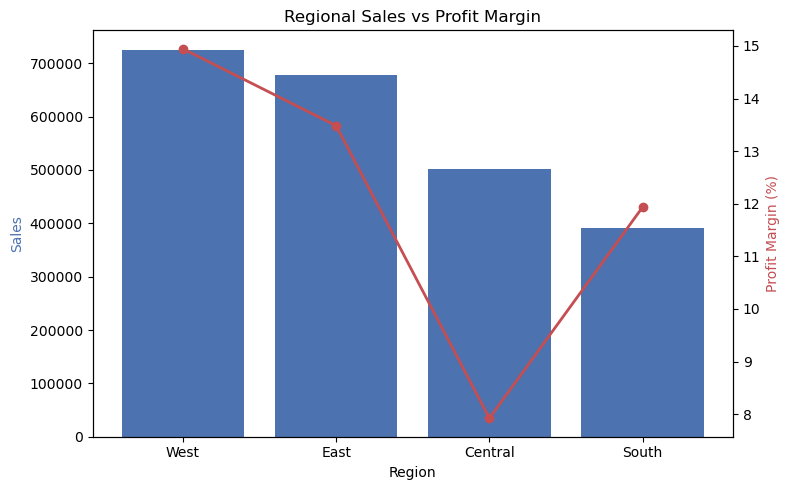

In [22]:
# --- 4. Region: sales vs margin ---
fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.bar(region_stats.index, region_stats["Sales"], color="#4C72B0")
ax1.set_xlabel("Region")
ax1.set_ylabel("Sales", color="#4C72B0")
ax2 = ax1.twinx()
ax2.plot(region_stats.index, region_stats["Margin %"], color="#C44E52", marker="o", linewidth=2)
ax2.set_ylabel("Profit Margin (%)", color="#C44E52")
ax1.set_title("Regional Sales vs Profit Margin")
plt.tight_layout()
plt.savefig("region_sales_margin.png", dpi=150)
plt.show()

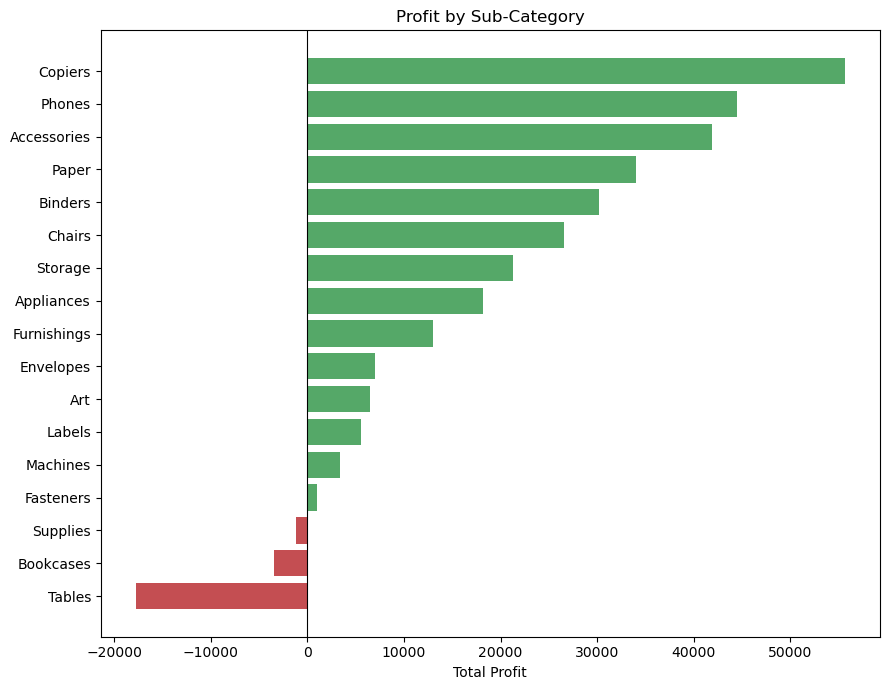

In [23]:
# --- 5. Profit by sub-category (losses in red) ---
colors = ["#C44E52" if v < 0 else "#55A868" for v in subcat_profit.values]
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(subcat_profit.index, subcat_profit.values, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Profit by Sub-Category")
ax.set_xlabel("Total Profit")
plt.tight_layout()
plt.savefig("profit_by_subcategory.png", dpi=150)
plt.show()

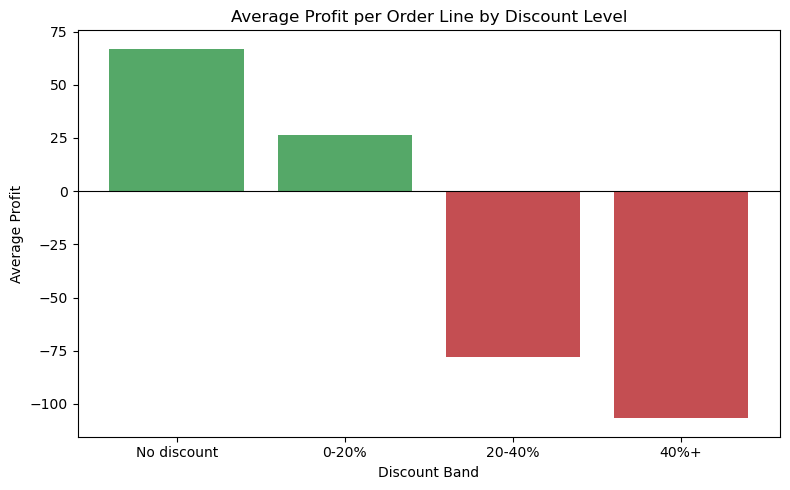

In [24]:
# --- 6. Average profit per order line by discount band ---
band_colors = ["#55A868" if v > 0 else "#C44E52" for v in discount_impact["mean"]]
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(discount_impact.index.astype(str), discount_impact["mean"], color=band_colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Average Profit per Order Line by Discount Level")
ax.set_xlabel("Discount Band")
ax.set_ylabel("Average Profit")
plt.tight_layout()
plt.savefig("profit_by_discount.png", dpi=150)
plt.show()

### Exporting One-Page Summary with Charts and Recommendations

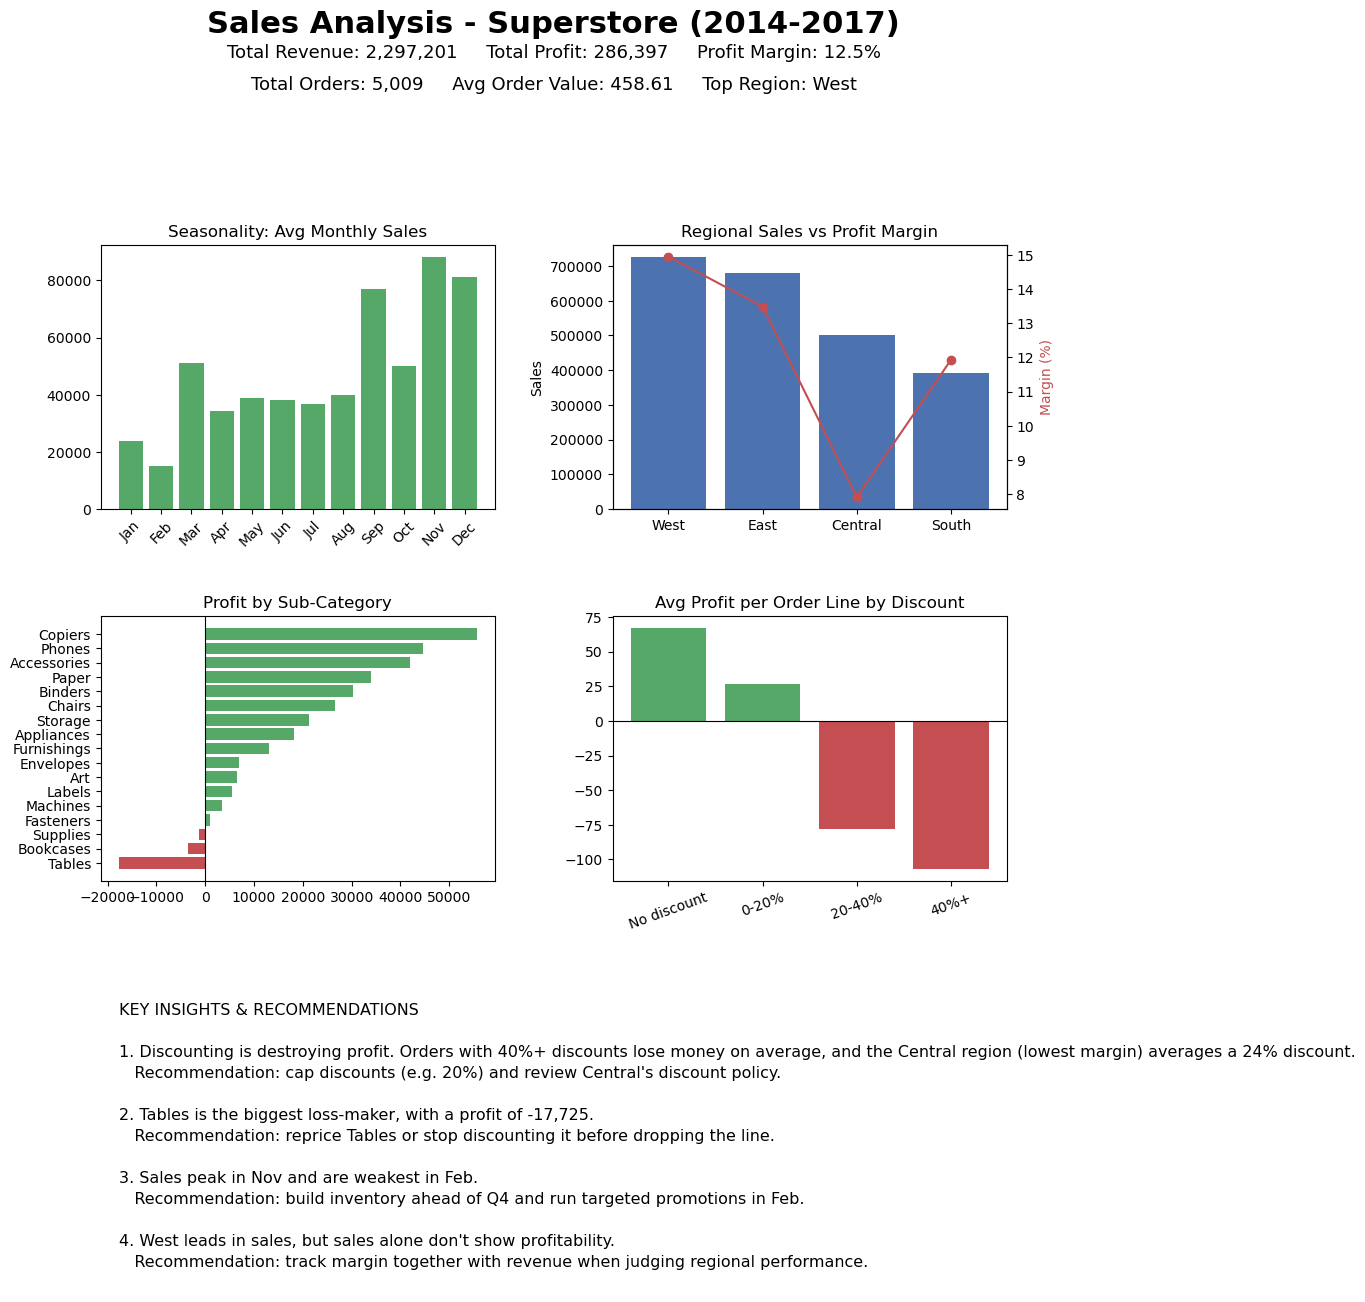

In [25]:
from matplotlib.gridspec import GridSpec

# --- Pulling the key facts ---
top_region = region_stats.index[0]
low_margin_region = region_stats["Margin %"].idxmin()
worst_subcat = subcat_profit.index[0]
worst_subcat_profit = subcat_profit.iloc[0]
peak_month = month_names[monthly_avg.idxmax() - 1]
low_month = month_names[monthly_avg.idxmin() - 1]
central_discount = df[df["Region"] == low_margin_region]["Discount"].mean() * 100

# --- Building the one-page layout ---
fig = plt.figure(figsize=(11.69, 16.54))  # A4 portrait
gs = GridSpec(4, 2, figure=fig, height_ratios=[0.9, 2, 2, 2.3], hspace=0.45, wspace=0.3)

# Header + KPIs
ax = fig.add_subplot(gs[0, :])
ax.axis("off")
ax.text(0.5, 0.88, "Sales Analysis - Superstore (2014-2017)", ha="center",
        fontsize=22, fontweight="bold")
kpi_text = (
    f"Total Revenue: {total_revenue:,.0f}     Total Profit: {total_profit:,.0f}     "
    f"Profit Margin: {profit_margin:.1f}%\n"
    f"Total Orders: {total_orders:,}     Avg Order Value: {avg_order_value:,.2f}     "
    f"Top Region: {top_region}"
)
ax.text(0.5, 0.4, kpi_text, ha="center", fontsize=13, linespacing=2)

# Chart 1: Seasonality
ax = fig.add_subplot(gs[1, 0])
ax.bar(month_names, monthly_avg.values, color="#55A868")
ax.set_title("Seasonality: Avg Monthly Sales")
ax.tick_params(axis="x", rotation=45)

# Chart 2: Region sales vs margin
ax = fig.add_subplot(gs[1, 1])
ax.bar(region_stats.index, region_stats["Sales"], color="#4C72B0")
ax.set_title("Regional Sales vs Profit Margin")
ax.set_ylabel("Sales")
ax2 = ax.twinx()
ax2.plot(region_stats.index, region_stats["Margin %"], color="#C44E52", marker="o")
ax2.set_ylabel("Margin (%)", color="#C44E52")

# Chart 3: Profit by sub-category
ax = fig.add_subplot(gs[2, 0])
colors = ["#C44E52" if v < 0 else "#55A868" for v in subcat_profit.values]
ax.barh(subcat_profit.index, subcat_profit.values, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Profit by Sub-Category")

# Chart 4: Profit by discount band
ax = fig.add_subplot(gs[2, 1])
band_colors = ["#55A868" if v > 0 else "#C44E52" for v in discount_impact["mean"]]
ax.bar(discount_impact.index.astype(str), discount_impact["mean"], color=band_colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Avg Profit per Order Line by Discount")
ax.tick_params(axis="x", rotation=20)

# Recommendations
ax = fig.add_subplot(gs[3, :])
ax.axis("off")
recs = (
    "KEY INSIGHTS & RECOMMENDATIONS\n\n"
    f"1. Discounting is destroying profit. Orders with 40%+ discounts lose money on average, "
    f"and the {low_margin_region} region (lowest margin) averages a {central_discount:.0f}% discount.\n"
    f"   Recommendation: cap discounts (e.g. 20%) and review {low_margin_region}'s discount policy.\n\n"
    f"2. {worst_subcat} is the biggest loss-maker, with a profit of {worst_subcat_profit:,.0f}.\n"
    f"   Recommendation: reprice {worst_subcat} or stop discounting it before dropping the line.\n\n"
    f"3. Sales peak in {peak_month} and are weakest in {low_month}.\n"
    f"   Recommendation: build inventory ahead of Q4 and run targeted promotions in {low_month}.\n\n"
    f"4. {top_region} leads in sales, but sales alone don't show profitability.\n"
    f"   Recommendation: track margin together with revenue when judging regional performance."
)
ax.text(0.02, 0.95, recs, ha="left", va="top", fontsize=11.5, linespacing=1.5, wrap=True)

plt.savefig("sales_summary_onepage.pdf", bbox_inches="tight")
plt.savefig("sales_summary_onepage.png", dpi=150, bbox_inches="tight")
plt.show()

In [26]:
text_summary = f"""SALES ANALYSIS SUMMARY - SUPERSTORE (2014-2017)
================================================
Total Revenue: {total_revenue:,.2f}
Total Profit: {total_profit:,.2f}
Profit Margin: {profit_margin:.2f}%
Total Orders: {total_orders:,}
Average Order Value: {avg_order_value:,.2f}

Top Region by Sales: {top_region}
Lowest-Margin Region: {low_margin_region}
Biggest Loss-Making Sub-Category: {worst_subcat} ({worst_subcat_profit:,.2f})
Strongest Month: {peak_month} | Weakest Month: {low_month}

Recommendations:
1. Cap discounts at around 20%; 40%+ discounts lose money on average.
2. Reprice {worst_subcat} and stop discounting it.
3. Prepare inventory for Q4 and run promotions in {low_month}.
4. Judge regions on margin as well as revenue.
"""

with open("sales_summary.txt", "w", encoding="utf-8") as f:
    f.write(text_summary)

print(text_summary)

SALES ANALYSIS SUMMARY - SUPERSTORE (2014-2017)
Total Revenue: 2,297,200.86
Total Profit: 286,397.02
Profit Margin: 12.47%
Total Orders: 5,009
Average Order Value: 458.61

Top Region by Sales: West
Lowest-Margin Region: Central
Biggest Loss-Making Sub-Category: Tables (-17,725.48)
Strongest Month: Nov | Weakest Month: Feb

Recommendations:
1. Cap discounts at around 20%; 40%+ discounts lose money on average.
2. Reprice Tables and stop discounting it.
3. Prepare inventory for Q4 and run promotions in Feb.
4. Judge regions on margin as well as revenue.

